# Amortized methods in geostatistics

In [1]:
import matplotlib
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

import random
from tqdm import tqdm
import time

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

## Simulation

### Sampling

In [6]:
def sampling_matern(lambdaParent,lambdaDaughter,radiusCluster):

    # Simulation window parameters
    xMin = 0
    xMax = 1
    yMin = 0
    yMax = 1

    # Extended simulation windows parameters
    rExt = radiusCluster  # extension parameter -- use cluster radius
    xMinExt = xMin - rExt
    xMaxExt = xMax + rExt
    yMinExt = yMin - rExt
    yMaxExt = yMax + rExt

    # rectangle dimensions
    xDeltaExt = xMaxExt - xMinExt
    yDeltaExt = yMaxExt - yMinExt
    areaTotalExt = xDeltaExt * yDeltaExt  # area of extended rectangle

    # Simulate Poisson point process for the parents
    numbPointsParent = np.random.poisson(areaTotalExt * lambdaParent)  # Poisson number of points
    
    # x and y coordinates of Poisson points for the parent
    xxParent = xMinExt + xDeltaExt * np.random.uniform(0, 1, numbPointsParent)
    yyParent = yMinExt + yDeltaExt * np.random.uniform(0, 1, numbPointsParent)

    # Simulate Poisson point process for the daughters (ie final poiint process)
    numbPointsDaughter = np.random.poisson(lambdaDaughter, numbPointsParent) # np.random.poisson(lambdaDaughter*np.pi*((radiusCluster)**2), numbPointsParent);
    numbPoints = sum(numbPointsDaughter)

    # Generate the (relative) locations in polar coordinates by
    # simulating independent variables.
    theta = 2 * np.pi * np.random.uniform(0, 1, numbPoints)  # angular coordinates
    rho = radiusCluster * np.sqrt(np.random.uniform(0, 1, numbPoints))  # radial coordinates
    # Convert from polar to Cartesian coordinates
    xx0 = rho * np.cos(theta)
    yy0 = rho * np.sin(theta)

    # replicate parent points (ie centres of disks/clusters)
    xx = np.repeat(xxParent, numbPointsDaughter)
    yy = np.repeat(yyParent, numbPointsDaughter)

    # translate points (ie parents points are the centres of cluster disks)
    xx = xx + xx0
    yy = yy + yy0

    # thin points if outside the simulation window
    booleInside = ((xx >= xMin) & (xx <= xMax) & (yy >= yMin) & (yy <= yMax))
    # retain points inside simulation window
    xx = xx[booleInside]
    yy = yy[booleInside]

    # keeping the same digits precision as the simtub
    data = {'x1': xx, 'x2': yy}
    sample = pd.DataFrame(data)

    return(sample)


def grid():
    return pd.DataFrame({'x1':np.repeat(np.linspace(0,1,100),100),'x2':np.tile(np.linspace(0,1,100),100)})

In [7]:
def simulation_matern(sample, theta_range, theta_std, plot=False):

    db = gl.Db_fromPandas(sample)
    db.setLocators(["x1","x2"],gl.ELoc.X)

    model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range*np.sqrt(8), param = 1, sill = theta_std**2)  # range is the practical range of Matérn with smoothness parameter = 1
    err = gl.simtub(None, db, model, None, nbsimu=1, seed=0, nbtuba = 1000)

    df_simu = pd.DataFrame({'Simu': db['z1']})
    db_simu = pd.concat([sample, df_simu],axis=1)

    if plot:
            fig, axs = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)

            axs.scatter(db_simu['x1'], db_simu['x2'], c=db_simu['Simu'], s=8) 
        
            axs.set_xlabel('x1')
            axs.set_ylabel('x2')
            axs.set_title('Simu Values with Selected Points')

            axs.set_xlim([0, 1])
            axs.set_ylim([0, 1])
            axs.axis('equal')

            plt.show()

    return db_simu

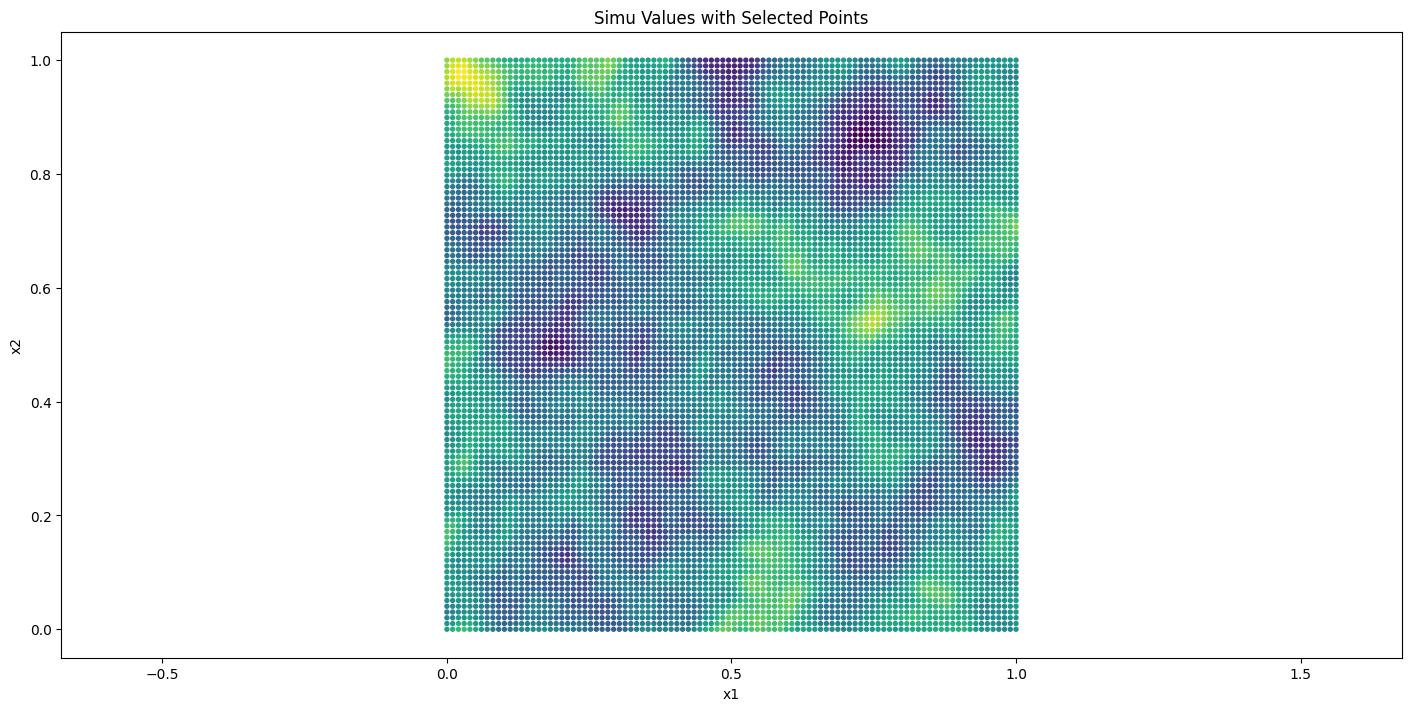

,x1,x2,Simu
0,0.0,0.000000,0.820661
1,0.0,0.010101,0.589607
2,0.0,0.020202,0.224117
3,0.0,0.030303,-0.042037
4,0.0,0.040404,0.052424
...,...,...,...
9995,1.0,0.959596,0.273673
9996,1.0,0.969697,0.117743
9997,1.0,0.979798,0.127673
9998,1.0,0.989899,0.354456


In [8]:
sample = grid()
theta_range, theta_std = .1, 1.
simulation_matern(sample, theta_range, theta_std, plot=True)

### Graphs

In [25]:
def create_edge_graph(sample, threshold=.4, max_neighbors=10):
    coords = sample[['x1', 'x2']].values
    node_features = torch.tensor(sample[['Simu']].values, dtype=torch.float)

    nearest_neighbors = cKDTree(coords) 

    edge_sources = []
    edge_destinations = []
    edge_features = []

    for i, coord in enumerate(coords):
        neighbors = nearest_neighbors.query_ball_point(coord, r=threshold)
        neighbors = [j for j in neighbors if j != i]

        if len(neighbors) > max_neighbors:
            neighbors = np.random.choice(neighbors, max_neighbors, replace=False)

        dists = np.linalg.norm(coords[neighbors] - coord, axis=1)
            
        edge_sources.extend(np.repeat(i,len(neighbors))) # [i] * len(neighbors)
        edge_destinations.extend(neighbors) # neighbors.tolist()

        edge_sources.extend(neighbors)
        edge_destinations.extend(np.repeat(i,len(neighbors)))
        
        edge_features.extend(np.concatenate([dists, dists]))

    edge_index = torch.tensor([edge_sources, edge_destinations], dtype=torch.long)
    edge_attr = torch.tensor(edge_features, dtype=torch.float).unsqueeze(1) # .view(-1, 1)

    return Data(x=node_features, edge_index=edge_index, edge_attr=edge_attr)


In [26]:
def datamaker_graph(constant_product, n):

    datalist=[]
    
    range_list = np.random.uniform(0.05,0.4,n)
    std_list = np.random.uniform(0.1,1.,n)
    lambdaParent = np.random.uniform(20, 60,n)
    lambdaDaughter = constant_product / lambdaParent

    threshold = 0.4
    max_neighbors = 5
    radiusCluster = 0.15

    t = tqdm(range(0, n),total=n)
    
    for i in t:
        
        sample = sampling_matern(lambdaParent[i],lambdaDaughter[i],radiusCluster)
        simu = simulation_matern(sample, range_list[i], std_list[i])
        data = create_edge_graph(simu, threshold, max_neighbors)

        ### log ici ?
        data.theta = torch.tensor((range_list[i], std_list[i]))
        #data.theta = torch.log(data.theta)
        # data.x = torch.log(data.x)

        data.sizes = torch.tensor(len(data.x))
        
        datalist.append(data)               
    
    return datalist

In [27]:
constant_product = 1000
n = 1000
datalist = datamaker_graph(constant_product, n)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [04:28<00:00,  3.73it/s]


In [28]:
datalist[:5]

[Data(x=[940, 1], edge_index=[2, 9400], edge_attr=[9400, 1], theta=[2], sizes=940),
 Data(x=[1044, 1], edge_index=[2, 10440], edge_attr=[10440, 1], theta=[2], sizes=1044),
 Data(x=[762, 1], edge_index=[2, 7620], edge_attr=[7620, 1], theta=[2], sizes=762),
 Data(x=[853, 1], edge_index=[2, 8530], edge_attr=[8530, 1], theta=[2], sizes=853),
 Data(x=[1050, 1], edge_index=[2, 10500], edge_attr=[10500, 1], theta=[2], sizes=1050)]

In [29]:
class GraphSetDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
        data = self.datalist[idx]
        
        theta = data.theta.float()
        
        return Data(x=data.x,edge_index=data.edge_index,edge_attr=data.edge_attr,sizes=data.sizes), theta

In [30]:
dataset = GraphSetDataset(datalist)

batch_size = 20

loader = DataLoader(dataset, batch_size, shuffle=True)

### Grid

In [9]:
def points_to_grid(sample, nb_bins=100):
    
    bin_size = 1.0 / nb_bins

    x1 = torch.tensor(sample['x1'].values, dtype=torch.float32)
    x2 = torch.tensor(sample['x2'].values, dtype=torch.float32)
    values = torch.tensor(sample['Simu'].values, dtype=torch.float32)
    
    ix = torch.clamp((x1 / bin_size).long(), max=nb_bins - 1)
    iy = torch.clamp((x2 / bin_size).long(), max=nb_bins - 1)
    
    value_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
    count_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
    
    flat_idx = ix * nb_bins + iy
    
    value_flat.index_add_(0, flat_idx, values)
    count_flat.index_add_(0, flat_idx, torch.ones_like(values))

    value_grid = value_flat.view(nb_bins, nb_bins)
    count_grid = count_flat.view(nb_bins, nb_bins)

    mean_grid = torch.empty_like(value_grid)
    mean_grid[:] = float('nan')
    mask = count_grid > 0
    mean_grid[mask] = value_grid[mask] / count_grid[mask]

    return mean_grid

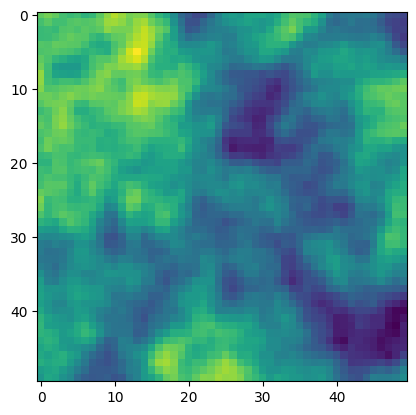

In [10]:
sample = grid()
theta_range, theta_std = .1, 1.
simu = simulation_matern(sample, theta_range, theta_std)
plt.imshow(points_to_grid(simu,nb_bins=50))

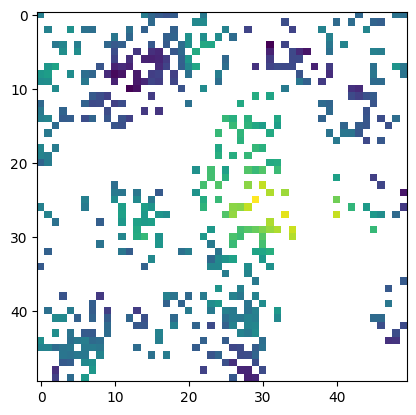

In [11]:
sample = sampling_matern(20,20,.1)
theta_range, theta_std = .1, 1.
simu = simulation_matern(sample, theta_range, theta_std)
plt.imshow(points_to_grid(simu,nb_bins=50))

In [13]:
def datamaker_grid(constant_product, n):

    datalist=[]
    
    range_list = np.random.uniform(0.05,0.4,n)
    std_list = np.random.uniform(0.1,1.,n)
    lambdaParent = np.random.uniform(20, 60,n)
    lambdaDaughter = constant_product / lambdaParent

    radiusCluster = 0.15
    bins = 100
    
    t = tqdm(range(0, n),total=n)
    
    for i in t:
        
        sample = sampling_matern(lambdaParent[i],lambdaDaughter[i],radiusCluster)
        simu = simulation_matern(sample, range_list[i], std_list[i])
        points = points_to_grid(simu, bins)

        data = Data(x=points, theta=torch.tensor((range_list[i], std_list[i])))

        ### log ici ?
        # data.theta = torch.log(data.theta)
        # data.x = torch.log(data.x)
        
        datalist.append(data)               
    
    return datalist

In [14]:
constant_product = 1000
n = 1000
datalist = datamaker_grid(constant_product, n)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [02:17<00:00,  7.29it/s]


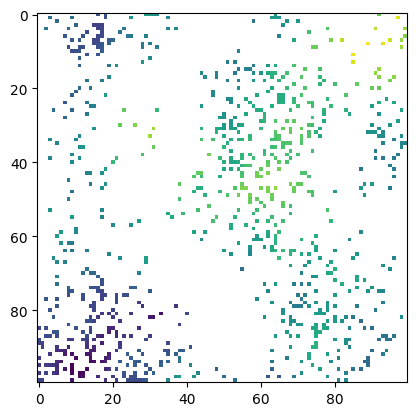

In [15]:
plt.imshow(datalist[4].x)

In [16]:
class GridSetDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
        
        data = self.datalist[idx]
        
        x = data.x                      # [H, W]
        x = torch.nan_to_num(x, nan=0.)
        
        mask = (~torch.isnan(data.x)).float()
        
        x = torch.stack([x, mask], dim=0)  # [2, H, W]
        theta = data.theta.float()
        
        return x, theta

In [17]:
dataset = GridSetDataset(datalist)

batch_size = 20

loader = DataLoader(dataset, batch_size, shuffle=True)

## GNN

In [31]:
def w_first_half(distances, threshold=0.4, nb_intervals=10, epsilon=1e-5, std=0.00375):
    """
    exp(-(d_jj' _ µ_1)²/σ²), ..., exp(-(d_jj' _ µ_10)²/σ²)
    """
    
    if torch.max(distances) < epsilon or torch.max(distances) > threshold:
        raise ValueError(distances,threshold,"Distance should be within the range (0, threshold]")
    
    interval_length = threshold / nb_intervals
    interval_index = (distances / interval_length).to(torch.int)
    interval_index[interval_index == nb_intervals] -= 1

    means = torch.arange(interval_length/2,threshold,interval_length).tile((len(distances),1))
    
    res = distances.tile((1,nb_intervals))
    res = (res - means)**2 / (2 * std**2)
    
    return torch.exp(-res)


def w_first_half_old(distance, threshold=0.4, epsilon=1e-5):
    if distance < epsilon or distance > threshold:
        raise ValueError(distance,threshold,"Distance should be within the range (0, threshold]")
    
    interval_length = threshold / 10
    interval_index = int(distance / interval_length)
    if interval_index == 10:
        interval_index = 9
    
    one_hot = torch.zeros(10, device=device)
    one_hot[interval_index] = 1
    
    return one_hot

In [32]:
class w_second_half(nn.Module):
    """
    ω(d_jj'), MLP
    """
    def __init__(self, input_dim, hidden_dim, edge_output_dim):
        super(w_second_half, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, edge_output_dim)
        ).to(device) 

    def forward(self, x):
        return self.mlp(x)

In [33]:
class w_tilde(nn.Module):
    """
    w̃_j(s_j, s_j') = w_j(s_j, s_j') ⊘ Σ_j'' w_j(s_j, s_j'') 

    w(d_jj') = [exp(-(d_jj' _ µ_1)²/σ²), ..., exp(-(d_jj' _ µ_10)²/σ²), ω(d_jj')]
    """
    def __init__(self, in_channels, edge_hidden_dim, edge_output_dim, threshold=.4):
        super(w_tilde, self).__init__()
        
        self.edge_mlp = w_second_half(in_channels, edge_hidden_dim, edge_output_dim)
        self.threshold = threshold
    
    def forward(self, data):

        x, edge_index, edge_attr = data.x.to(device), data.edge_index.to(device), data.edge_attr.to(device)

        w_first = w_first_half(edge_attr, threshold=self.threshold).to(device)
        # w_first = torch.stack([w_first_half_old(d.item(),self.threshold) for d in edge_attr]).to(device)
        w_second = self.edge_mlp(edge_attr)
        w = torch.cat((w_first, w_second), dim=1) 

        d = scatter(w, edge_index[0], reduce = 'sum')  # sum over all neighbors
        dtilde = d[edge_index[0]]  
        
        mask = dtilde != 0
        replacement_tensor = torch.ones_like(mask, device=device) * 1e-5
        wtilde = torch.where(mask, w / dtilde, replacement_tensor) 
        
        data.edge_attr_wtilde = wtilde
        
        return data

In [34]:
class h(MessagePassing):  
    """
    h_j = g(Γ_1 @ h_(j-1) + Γ_2 @ ĥ_j + b), Convolution layer

    ĥ_j = Σ_j' w(d_jj') × ρ(h_j, h_j'), with h_j, h_j' from previous layer

    ρ(h_j, h_j') = |a h_j - (1-a) h_j'|^b
    """
    
    def __init__(self, hidden_channels, moovingvaluegamma1):
        super().__init__(aggr='add')
        
        self.a = nn.Parameter(torch.rand(1, device=device)) # a in [0, 1]
        self.b = nn.Parameter(torch.rand(1, device=device) + 1) # b > 0
        
        self.gamma1 = nn.Parameter(torch.rand(hidden_channels, moovingvaluegamma1, device=device))
        self.gamma2 = nn.Parameter(torch.rand(hidden_channels, hidden_channels, device=device))
        
        self.biax = nn.Parameter(torch.rand(hidden_channels,1, device=device))
    
    def forward(self, x: torch.Tensor, edge_index: torch.Tensor,
                edge_attr: torch.Tensor ) -> torch.Tensor:
        
        hbar = self.propagate(edge_index, x = x, edge_attr = edge_attr) 
        
        hbar = hbar.transpose(1,0)
        x = x.transpose(1,0)
        
        out = self.gamma1 @ x + self.gamma2 @ hbar + self.biax
        out = out.transpose(1,0)
        out = torch.nn.ReLU()(out).squeeze()

        return out

    def message(self, x_i, x_j, edge_attr: torch.Tensor) -> torch.Tensor:
        
        rho = (torch.abs(self.a * x_i - (1 - self.a) * x_j)) ** self.b

        return rho * edge_attr


In [35]:
class exp_final(nn.Module):
    def forward(self, x):
        return torch.exp(x)

class phi(nn.Module):
    """
    ɸ, MLP, mapping layer
    """
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(phi, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
            # exp_final(), # In case we are looking to log of the targets
        )

    def forward(self, pooled_feature):
        device=pooled_feature.device
        out = self.mlp(pooled_feature.to(device))
        return out

In [36]:
class GNN_network(nn.Module):

    def __init__(self, in_channels, gamma1_1, gamma1_2, hidden_dim, edge_hidden_dim, edge_output_dim, threshold,mapping_hidden_dim, final_output_dim):# final_output_dim, mapping_hidden_dim, threshold):
        super(GNN_network, self).__init__()
        
        self.wtilde_initial = w_tilde(in_channels, edge_hidden_dim, edge_output_dim, threshold)
        self.special_conv1 = h(hidden_dim,gamma1_1)

        # We can repeat those two lines
        self.wtilde = w_tilde(in_channels, edge_hidden_dim, edge_output_dim, threshold) 
        self.special_conv2 = h(hidden_dim,gamma1_2)
        
        self.mapping = phi(hidden_dim, mapping_hidden_dim, final_output_dim)

    def forward(self, data):
        data = data.to(device)
        
        data = self.wtilde_initial(data)
        data.x = self.special_conv1(x=data.x, edge_index=data.edge_index, edge_attr= data.edge_attr_wtilde)
        
        data=self.wtilde(data)
        data.x=self.special_conv2(x=data.x, edge_index=data.edge_index, edge_attr= data.edge_attr_wtilde)
        
        pooled_graphs = global_mean_pool(data.x, data.pool_index.to(device)) 
        
        out = self.mapping(pooled_graphs)
        out = out.view(-1)
        
        return out

In [37]:
model = GNN_network(in_channels=1,
                 gamma1_1=1,
                 gamma1_2=20 ,
                 hidden_dim=20,
                 edge_hidden_dim=128,
                 edge_output_dim=10,
                 threshold=0.40,
                 mapping_hidden_dim=128,
                 final_output_dim=2)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [38]:
def train_gnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = 0.0

    for batched_data, theta in loader:
        optimizer.zero_grad()

        batched_data, theta = batched_data.to(device), theta.to(device)

        pool_index = torch.repeat_interleave(
            torch.arange(len(batched_data.sizes), device=device),
            batched_data.sizes
        )
        batched_data.pool_index = pool_index

        current_batch_size = theta.size(0)

        theta = theta.view(current_batch_size, 2) 

        output = model(batched_data)
        output = torch.reshape(output,(current_batch_size,2))
        
        batch_loss = MAE(output, theta)

        # print(output[0], theta_batch[0])
        
        batch_loss.backward()
        optimizer.step()

        sum_loss += batch_loss.item()

    return sum_loss / len(loader)



Epoch 50/50: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [34:16<00:00, 41.13s/it, loss=0.1038]


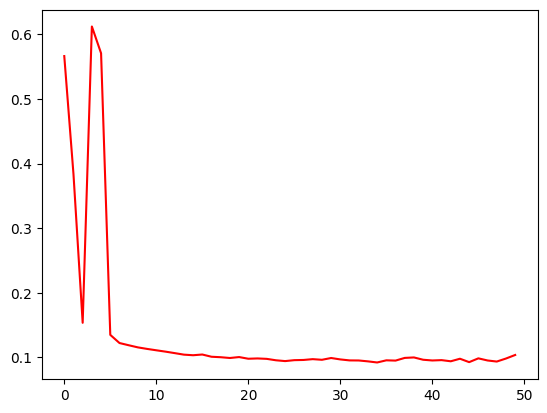

In [39]:
n_epochs = 50
Loss=[]

n = len(dataset)
t = tqdm(range(0, n_epochs),total=n_epochs)

for epoch in t:
    
    loss = train_gnn(
        model,
        optimizer,
        loader,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss:.4f}")
    Loss.append(loss)

matplotlib.pyplot.plot(np.array(Loss), 'r')

## CNN

In [18]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)  # ~vec(·) 
        self.dense = nn.Sequential(
            nn.Linear(hidden, 64),
            nn.ReLU(),
            nn.Linear(64, out_dim)  
        )

    def forward(self, x):
        h = self.conv(x)           
        h = self.pool(h).view(h.size(0), -1)
        out = self.dense(h)
        return out

In [19]:
def train_cnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = 0.0

    for x, theta in loader:
        optimizer.zero_grad()

        x, theta = x.to(device), theta.to(device)

        output = model(x)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        sum_loss += batch_loss.item()

    return sum_loss / len(loader)



In [20]:
model_cnn = CNN_network().to(device)

optimizer = torch.optim.Adam(model_cnn.parameters(), lr=1e-4)

Epoch 50/50: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [18:16<00:00, 21.94s/it, loss=0.0893]


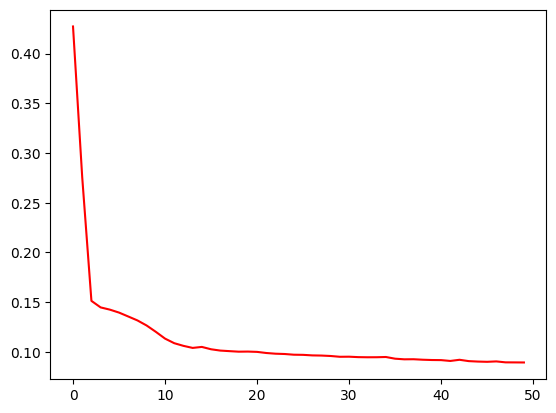

In [21]:
n_epochs = 50
Loss=[]

n = len(dataset)
t = tqdm(range(0, n_epochs),total=n_epochs)

for epoch in t:
    
    loss = train_cnn(
        model_cnn,
        optimizer,
        loader,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss:.4f}")
    Loss.append(loss)

matplotlib.pyplot.plot(np.array(Loss), 'r')